In [12]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Load the data
import pandas as pd

# Load the data
data = pd.read_csv('C:/Users/student/Afterlasso.csv')

In [13]:
data['DX']=data['DX'].map({'AD':0, 'MCI':1, 'CN':2})

In [14]:
data['VISCODE']=data['VISCODE'].map({'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24})

In [15]:
data=pd.get_dummies(data,columns=['PTGENDER'])

In [16]:
cols=data.columns.tolist()
cols.remove('DX')
cols.append('DX')
data=data[cols]

In [17]:
data

,RID,VISCODE,AGE,PTEDUCAT,APOE4,CDRSB,ADAS11,ADAS13,MMSE,RAVLT_immediate,...,ST98SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX
0,3,0,81.3,18,1,4.5,22.00,31.00,20,22.0,...,1734.0,10387.0,3316.0,3304.0,741.5,239.7,22.83,0,1,0
1,3,6,81.3,18,1,6.0,19.00,30.00,24,19.0,...,1868.0,9311.0,3138.0,3173.0,741.5,239.7,22.83,0,1,0
2,3,12,81.3,18,1,3.5,24.00,35.00,17,31.0,...,1898.0,9736.0,3240.0,3235.0,601.4,251.7,24.18,0,1,0
3,3,18,81.3,18,1,3.5,24.00,35.00,17,31.0,...,1898.0,9736.0,3240.0,3235.0,601.4,251.7,24.18,0,1,0
4,3,24,81.3,18,1,8.0,25.67,37.67,19,23.0,...,1915.0,9316.0,3097.0,3314.0,601.4,251.7,24.18,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5700,5106,0,74.1,16,0,4.0,30.00,42.00,20,18.0,...,2129.0,9280.0,3127.0,1789.0,845.1,436.4,45.50,0,1,0
5701,5106,6,74.1,16,0,6.0,26.00,38.00,17,12.0,...,2129.0,9280.0,3127.0,1789.0,845.1,436.4,45.50,0,1,0
5702,5106,12,74.1,16,0,6.0,26.00,38.00,17,12.0,...,2129.0,9280.0,3127.0,1789.0,845.1,436.4,45.50,0,1,0
5703,5106,18,74.1,16,0,6.0,26.00,38.00,17,12.0,...,2129.0,9280.0,3127.0,1789.0,845.1,436.4,45.50,0,1,0


In [ ]:
Data Concatenation code

In [18]:
# Create separate dataframes for each visit
bl_data = data[data['VISCODE'] == 0].drop('VISCODE', axis=1)
m06_data = data[data['VISCODE'] == 6].drop('VISCODE', axis=1)
m12_data = data[data['VISCODE'] == 12].drop('VISCODE', axis=1)
m18_data = data[data['VISCODE'] == 18].drop('VISCODE', axis=1)
m24_data = data[data['VISCODE'] == 24].drop('VISCODE', axis=1)

# Merge the dataframes for each patient based on their ID
merged_data = pd.merge(bl_data, m06_data, on='RID', suffixes=('_bl', '_m06'))
merged_data12 = pd.merge(merged_data, m12_data, on='RID', suffixes=('', '_m12'))
merged_data18 = pd.merge(merged_data12, m18_data, on='RID', suffixes=('', '_m18'))
merged_data24 = pd.merge(merged_data18, m24_data, on='RID', suffixes=('', '_m24'))

In [19]:
merged_data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST98SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ABETA_UPENNBIOMK9_04_19_17_m06,TAU_UPENNBIOMK9_04_19_17_m06,PTAU_UPENNBIOMK9_04_19_17_m06,PTGENDER_Female_m06,PTGENDER_Male_m06,DX_m06
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,1868.0,9311.0,3138.0,3173.0,741.500000,239.700000,22.830000,0,1,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,1737.0,11501.0,3399.0,1532.0,547.300000,337.000000,33.430000,0,1,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,1289.0,9964.0,2848.0,1381.0,1064.913718,284.614621,27.130365,1,0,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,1725.0,8691.0,2956.0,1520.0,1064.913718,284.614621,27.130365,0,1,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,1355.0,9878.0,3324.0,1244.0,357.400000,329.900000,31.260000,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,1630.0,8757.0,3274.0,3381.0,998.200000,472.000000,47.150000,1,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,1492.0,8976.0,2891.0,3162.0,1064.913718,284.614621,27.130365,1,0,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,1809.0,12585.0,3583.0,1892.0,1087.000000,113.600000,9.020000,1,0,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,1978.0,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1


In [20]:
merged_data12

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST98SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,1898.0,9736.0,3240.0,3235.0,601.400000,251.700000,24.180000,0,1,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,1685.0,10541.0,3207.0,1554.0,472.800000,334.100000,34.040000,0,1,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,1262.0,9871.0,2835.0,1209.0,1064.913718,284.614621,27.130365,1,0,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,1725.0,8691.0,2956.0,1520.0,1064.913718,284.614621,27.130365,0,1,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,1330.0,9423.0,3556.0,1213.0,340.000000,287.700000,27.370000,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,1630.0,9649.0,3286.0,3475.0,998.200000,472.000000,47.150000,1,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,1363.0,9110.0,2969.0,2966.0,1064.913718,284.614621,27.130365,1,0,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,1860.0,12567.0,3533.0,1938.0,1087.000000,113.600000,9.020000,1,0,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,1978.0,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1


In [21]:
merged_data18

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST98SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,PTGENDER_Female_m18,PTGENDER_Male_m18,DX_m18
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,1898.0,9736.0,3240.0,3235.0,601.400000,251.700000,24.180000,0,1,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,1685.0,10541.0,3207.0,1554.0,472.800000,334.100000,34.040000,0,1,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,1210.0,9523.0,2780.0,1151.0,1064.913718,284.614621,27.130365,1,0,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,1725.0,8691.0,2956.0,1520.0,1064.913718,284.614621,27.130365,0,1,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,1330.0,9423.0,3556.0,1213.0,340.000000,287.700000,27.370000,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,1630.0,9649.0,3286.0,3475.0,998.200000,472.000000,47.150000,1,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,1363.0,9110.0,2969.0,2966.0,1064.913718,284.614621,27.130365,1,0,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,1860.0,12567.0,3533.0,1938.0,1087.000000,113.600000,9.020000,1,0,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,1978.0,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1


In [22]:
merged_data24

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST98SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m24,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m24,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m24,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m24,ABETA_UPENNBIOMK9_04_19_17_m24,TAU_UPENNBIOMK9_04_19_17_m24,PTAU_UPENNBIOMK9_04_19_17_m24,PTGENDER_Female_m24,PTGENDER_Male_m24,DX_m24
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,1915.0,9316.0,3097.0,3314.0,601.400000,251.700000,24.180000,0,1,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,1885.0,10526.0,3189.0,1676.0,472.800000,334.100000,34.040000,0,1,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,1210.0,9523.0,2780.0,1151.0,1064.913718,284.614621,27.130365,1,0,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,1608.0,8487.0,2860.0,1522.0,1064.913718,284.614621,27.130365,0,1,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,1313.0,9357.0,3323.0,1310.0,340.000000,287.700000,27.370000,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,1630.0,9649.0,3286.0,3475.0,998.200000,472.000000,47.150000,1,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,1221.0,8413.0,2865.0,2995.0,1064.913718,284.614621,27.130365,1,0,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,1773.0,12939.0,3575.0,2028.0,1363.000000,135.100000,11.020000,1,0,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,1978.0,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1


In [23]:
#Merging whole bl data with DX_m06 as target from m06_data
# Select only the required columns from m06_data
m06_data_selected = merged_data[['RID', 'DX_m06']]

# Merge the selected columns from m06_data with bl_data based on RID
merged_data1 = pd.merge(bl_data, m06_data_selected, on='RID', how='left')

In [24]:
merged_data1.to_csv('baseline.csv')

In [25]:
#Merging whole blandm06 data with DX_m12 as target from m12_data
# Select only the required columns from m12_data
m12_data_selected = merged_data12[['RID', 'DX']]

# Merge the selected columns from m06_data with bl_data based on RID
merged_data2 = pd.merge(merged_data, m12_data_selected, on='RID', how='left')

In [26]:
merged_data2

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ABETA_UPENNBIOMK9_04_19_17_m06,TAU_UPENNBIOMK9_04_19_17_m06,PTAU_UPENNBIOMK9_04_19_17_m06,PTGENDER_Female_m06,PTGENDER_Male_m06,DX_m06,DX
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,9311.0,3138.0,3173.0,741.500000,239.700000,22.830000,0,1,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,11501.0,3399.0,1532.0,547.300000,337.000000,33.430000,0,1,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,9964.0,2848.0,1381.0,1064.913718,284.614621,27.130365,1,0,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,8691.0,2956.0,1520.0,1064.913718,284.614621,27.130365,0,1,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,9878.0,3324.0,1244.0,357.400000,329.900000,31.260000,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,8757.0,3274.0,3381.0,998.200000,472.000000,47.150000,1,0,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,8976.0,2891.0,3162.0,1064.913718,284.614621,27.130365,1,0,1,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,12585.0,3583.0,1892.0,1087.000000,113.600000,9.020000,1,0,1,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1,1


In [27]:
merged_data2.to_csv('bl&m06.csv')

In [28]:
#Merging whole blandm06andm12 data with DX_m18 as target from m18_data
# Select only the required columns from m06_data
m18_data_selected = merged_data18[['RID', 'DX_m18']]

# Merge the selected columns from m06_data with bl_data based on RID
merged_data3 = pd.merge(merged_data12, m18_data_selected, on='RID', how='left')

In [29]:
merged_data3

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX,DX_m18
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,9736.0,3240.0,3235.0,601.400000,251.700000,24.180000,0,1,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,10541.0,3207.0,1554.0,472.800000,334.100000,34.040000,0,1,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,9871.0,2835.0,1209.0,1064.913718,284.614621,27.130365,1,0,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,8691.0,2956.0,1520.0,1064.913718,284.614621,27.130365,0,1,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,9423.0,3556.0,1213.0,340.000000,287.700000,27.370000,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,9649.0,3286.0,3475.0,998.200000,472.000000,47.150000,1,0,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,9110.0,2969.0,2966.0,1064.913718,284.614621,27.130365,1,0,1,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,12567.0,3533.0,1938.0,1087.000000,113.600000,9.020000,1,0,1,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1,1


In [30]:
merged_data3.to_csv('bl&m06&m12.csv')

In [31]:
merged_data1

,RID,AGE,PTEDUCAT,APOE4,CDRSB,ADAS11,ADAS13,MMSE,RAVLT_immediate,RAVLT_learning,...,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX,DX_m06
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,10387.0,3316.0,3304.0,741.500000,239.700000,22.830000,0,1,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,11579.0,3387.0,1623.0,547.300000,337.000000,33.430000,0,1,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,9641.0,2781.0,1035.0,1064.913718,284.614621,27.130365,1,0,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,9069.0,2965.0,1536.0,1064.913718,284.614621,27.130365,0,1,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,10209.0,3368.0,1046.0,357.400000,329.900000,31.260000,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,9945.0,3135.0,3160.0,998.200000,472.000000,47.150000,1,0,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,8377.0,2947.0,3216.0,1064.913718,284.614621,27.130365,1,0,1,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,12355.0,3550.0,2050.0,1087.000000,113.600000,9.020000,1,0,1,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,9831.0,2909.0,2017.0,1923.000000,228.600000,19.010000,0,1,1,1


In [32]:
# Select only the required columns from m06_data
m24_data_selected = merged_data24[['RID', 'DX_m24']]

# Merge the selected columns from m06_data with bl_data based on RID
merged_data4 = pd.merge(merged_data18, m24_data_selected, on='RID', how='left')

In [33]:
merged_data4

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST99CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST99SA_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST9SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,PTGENDER_Female_m18,PTGENDER_Male_m18,DX_m18,DX_m24
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,9736.0,3240.0,3235.0,601.400000,251.700000,24.180000,0,1,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,10541.0,3207.0,1554.0,472.800000,334.100000,34.040000,0,1,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,9523.0,2780.0,1151.0,1064.913718,284.614621,27.130365,1,0,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,8691.0,2956.0,1520.0,1064.913718,284.614621,27.130365,0,1,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,9423.0,3556.0,1213.0,340.000000,287.700000,27.370000,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1136,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,9649.0,3286.0,3475.0,998.200000,472.000000,47.150000,1,0,0,0
1137,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,9110.0,2969.0,2966.0,1064.913718,284.614621,27.130365,1,0,1,1
1138,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,12567.0,3533.0,1938.0,1087.000000,113.600000,9.020000,1,0,1,1
1139,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,10428.0,3036.0,1933.0,1923.000000,228.600000,19.010000,0,1,1,1


In [34]:
merged_data4.to_csv('bl&m06&m12&m18.csv')

In [1]:
import pandas as pd

# read the changed_patients.csv file into a pandas DataFrame
changed_df = pd.read_csv('C:/Users/student/Downloads/AD less features/bl(less).csv')

# read the specific_changed_patients.csv file into a pandas DataFrame
specific_df = pd.read_csv('C:/Users/student/Downloads/specific_changed_patients.csv')

# create a new DataFrame that excludes the specific patients based on RID
excluded_df = changed_df[~changed_df['RID'].isin(specific_df['RID'])]

# save the new DataFrame to a CSV file
excluded_df.to_csv('bl(lessexc).csv', index=False)

In [2]:
import pandas as pd

# read the changed_patients.csv file into a pandas DataFrame
changed_df = pd.read_csv('C:/Users/student/Downloads/AD less features/bl&m06(less).csv')

# read the specific_changed_patients.csv file into a pandas DataFrame
specific_df = pd.read_csv('C:/Users/student/Downloads/specific_changed_patients.csv')

# create a new DataFrame that excludes the specific patients based on RID
excluded_df = changed_df[~changed_df['RID'].isin(specific_df['RID'])]

# save the new DataFrame to a CSV file
excluded_df.to_csv('bl&m06(lessexc).csv', index=False)

In [3]:
import pandas as pd

# read the changed_patients.csv file into a pandas DataFrame
changed_df = pd.read_csv('C:/Users/student/Downloads/AD less features/bl&m06&m12(less).csv')

# read the specific_changed_patients.csv file into a pandas DataFrame
specific_df = pd.read_csv('C:/Users/student/Downloads/specific_changed_patients.csv')

# create a new DataFrame that excludes the specific patients based on RID
excluded_df = changed_df[~changed_df['RID'].isin(specific_df['RID'])]

# save the new DataFrame to a CSV file
excluded_df.to_csv('bl&m06&m12(lessexc).csv', index=False)

In [4]:
import pandas as pd

# read the changed_patients.csv file into a pandas DataFrame
changed_df = pd.read_csv('C:/Users/student/Downloads/AD less features/bl&m06&m12&m18(less).csv')

# read the specific_changed_patients.csv file into a pandas DataFrame
specific_df = pd.read_csv('C:/Users/student/Downloads/specific_changed_patients.csv')

# create a new DataFrame that excludes the specific patients based on RID
excluded_df = changed_df[~changed_df['RID'].isin(specific_df['RID'])]

# save the new DataFrame to a CSV file
excluded_df.to_csv('bl&m06&m12&m18(lessexc).csv', index=False)

In [64]:
import pandas as pd

# read the changes.csv file into a pandas DataFrame
df = pd.read_csv('C:/Users/student/Downloads/excluded_patients.csv')

# calculate the number of patients that converted from 1 to 0 at any time visit
#num_1_to_0 = len(df[(df['DX_bl'] == 1) & (df['DX_m06'] == 0) & (df['DX'] == 0) & (df['DX_m18'] == 0) & (df['DX_m24'] == 0)])
num_1_to_0= len(df[((df['DX_bl'] == 1) & (df['DX_m06'] == 1) & (df['DX'] == 1) & (df['DX_m18'] == 1) & (df['DX_m24'] == 1)) | ((df['DX_bl'] == 2) & (df['DX_m06'] == 0) & (df['DX'] == 1) & (df['DX_m18'] == 1) & (df['DX_m24'] == 1))])
# calculate the number of patients that converted from 2 to 0 at any time visit
num_2_to_0 = len(df[(df['DX_bl'] == 2) & (df['DX_m06'] == 0) & (df['DX'] == 0) & (df['DX_m18'] == 0) & (df['DX_m24'] == 0)])

# calculate the number of patients that converted from 2 to 1 at any time visit
num_2_to_1 = len(df[((df['DX_bl'] == 2) & (df['DX_m06'] == 1) & (df['DX'] == 1) & (df['DX_m18'] == 1) & (df['DX_m24'] == 1)) | ((df['DX_bl'] == 2) & (df['DX_m06'] == 0) & (df['DX'] == 1) & (df['DX_m18'] == 1) & (df['DX_m24'] == 1))])

# print the results
print("Number of patients that converted from 1 to 0:", num_1_to_0)
print("Number of patients that converted from 2 to 0:", num_2_to_0)
print("Number of patients that converted from 2 to 1:", num_2_to_1)

Number of patients that converted from 1 to 0: 27
Number of patients that converted from 2 to 0: 0
Number of patients that converted from 2 to 1: 4


In [65]:
import pandas as pd

# read the changes.csv file into a pandas DataFrame
df = pd.read_csv('C:/Users/student/Downloads/excluded_patients.csv')

# calculate the number of patients that converted from 1 to 0 at any time visit
num_1_to_0 = len(df[(df['DX_bl'] == 1) & (df['DX_m06'] == 0) & (df['DX'] == 0) & (df['DX_m18'] == 0) & (df['DX_m24'] == 0)])

# calculate the number of patients that converted from 2 to 0 at any time visit
num_2_to_0 = len(df[(df['DX_bl'] == 2) & (df['DX_m06'] == 0) & (df['DX'] == 0) & (df['DX_m18'] == 0) & (df['DX_m24'] == 0)])

# calculate the number of patients that converted from 2 to 1 at any time visit
num_2_to_1 = len(df[((df['DX_bl'] == 2) & (df['DX_m06'] == 1) & (df['DX'] == 1) & (df['DX_m18'] == 1) & (df['DX_m24'] == 1)) | ((df['DX_bl'] == 2) & (df['DX_m06'] == 0) & (df['DX'] == 1) & (df['DX_m18'] == 1) & (df['DX_m24'] == 1))])

# print the results
print("Number of patients that converted from 1 to 0:", num_1_to_0)
print("Number of patients that converted from 2 to 0:", num_2_to_0)
print("Number of patients that converted from 2 to 1:", num_2_to_1)

Number of patients that converted from 1 to 0: 27
Number of patients that converted from 2 to 0: 0
Number of patients that converted from 2 to 1: 4


# RF on baseline.csv (Predict DX at M06)

In [66]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, classification_report
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Load the data
import pandas as pd

# Load the data
data = pd.read_csv('C:/Users/student/bl(lessexc).csv')

In [67]:
data

,RID,AGE,PTEDUCAT,APOE4,CDRSB,ADAS11,ADAS13,MMSE,RAVLT_immediate,RAVLT_learning,...,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX,DX_m06
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,2321.0,6300.0,2289.0,741.500000,239.700000,22.830000,0,1,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,2175.0,923.0,1820.0,547.300000,337.000000,33.430000,0,1,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,1810.0,713.0,1999.0,1064.913718,284.614621,27.130365,1,0,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2128.0,1867.0,1868.0,1064.913718,284.614621,27.130365,0,1,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2131.0,556.0,2011.0,357.400000,329.900000,31.260000,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,2709.0,1739.0,2310.0,998.200000,472.000000,47.150000,1,0,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2247.0,2011.0,1397.0,1064.913718,284.614621,27.130365,1,0,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,2922.0,183.0,2414.0,1087.000000,113.600000,9.020000,1,0,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,2823.0,322.0,1663.0,1923.000000,228.600000,19.010000,0,1,1,1


In [68]:
# Create the training and testing feature and label sets
x=data.iloc[:,1:-1] ## independent features
y=data.iloc[:,-1] ## dependent features

In [ ]:
####Data split

In [69]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30,random_state=42)

In [70]:
x_train

,AGE,PTEDUCAT,APOE4,CDRSB,ADAS11,ADAS13,MMSE,RAVLT_immediate,RAVLT_learning,RAVLT_perc_forgetting,...,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,0.575,1399.0,1369.0,2557.0,843.300000,549.200000,54.940000,1,0,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,0.633,2323.0,1135.0,2304.0,695.300000,237.700000,22.110000,1,0,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,0.587,2971.0,2567.0,1942.0,1459.000000,250.100000,21.350000,1,0,1
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,0.545,2380.0,1817.0,1415.0,1064.913718,284.614621,27.130365,0,1,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,0.525,2705.0,251.0,2054.0,1535.000000,142.500000,12.620000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,0.672,2478.0,377.0,1943.0,1064.913718,284.614621,27.130365,1,0,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,0.659,1244.0,825.0,2647.0,1064.913718,284.614621,27.130365,1,0,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,0.485,2187.0,2902.0,1581.0,1064.913718,284.614621,27.130365,0,1,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,0.535,2590.0,881.0,1770.0,927.500000,106.300000,8.870000,0,1,1


In [ ]:
###Hyperparameter tuning

In [71]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create a Random Forest classifier
clf = RandomForestClassifier(random_state=1)

In [72]:
# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=1), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]})

In [73]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best score: 0.972531819745442


In [74]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}


In [ ]:
### Model Train

In [75]:
# Train a Random Forest classifier on the training set
# Train the ExtraTrees classifier with the best hyperparameters
clf = RandomForestClassifier(**best_params)
clf.fit(x_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_split=10, n_estimators=200)

In [ ]:
### Model Test

In [76]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [77]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)

print("Confusion matrix:\n", confusion)

Training accuracy: 0.9869109947643979
Testing accuracy: 0.9695121951219512
Confusion matrix:
 [[ 49   9   0]
 [  0 163   1]
 [  0   0 106]]


In [78]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.84      0.92        58
           1       0.95      0.99      0.97       164
           2       0.99      1.00      1.00       106

    accuracy                           0.97       328
   macro avg       0.98      0.95      0.96       328
weighted avg       0.97      0.97      0.97       328



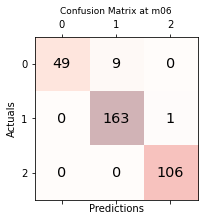

In [79]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Reds, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m06', fontsize=9)
plt.show()

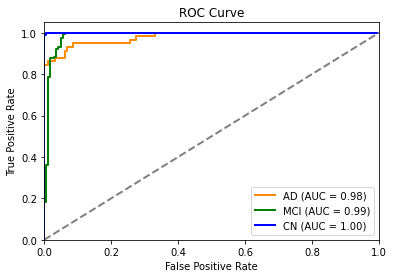

In [80]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# RF on bl&m06.csv ( predict DX at M12)

In [20]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Load the data
import pandas as pd

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06(lessexc).csv')

In [21]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ABETA_UPENNBIOMK9_04_19_17_m06,TAU_UPENNBIOMK9_04_19_17_m06,PTAU_UPENNBIOMK9_04_19_17_m06,DX_m06,DX
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3474.0,0.609,2491.0,6759.0,2380.0,741.500000,239.700000,22.830000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,2710.0,0.551,2284.0,877.0,1858.0,547.300000,337.000000,33.430000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2736.0,0.607,1734.0,730.0,2001.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,3022.0,0.662,2013.0,637.0,1794.0,357.400000,329.900000,31.260000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,2550.0,0.793,2505.0,1909.0,2245.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,3281.0,0.743,2312.0,2122.0,1386.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3275.0,0.658,2984.0,147.0,2536.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


In [22]:
# Create the training and testing feature and label sets
x=data.iloc[:,1:-1] ## independent features
y=data.iloc[:,-1] ## dependent features

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30,random_state=42)

In [24]:
x_train

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ABETA_UPENNBIOMK9_04_19_17_m06,TAU_UPENNBIOMK9_04_19_17_m06,PTAU_UPENNBIOMK9_04_19_17_m06,DX_m06
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,3267.0,2493.0,0.533,1638.0,1567.0,2498.0,843.300000,549.200000,54.940000,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,5273.0,3915.0,0.604,2351.0,1308.0,2298.0,695.300000,237.700000,22.110000,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,4656.0,4035.0,0.623,3258.0,2667.0,2026.0,1459.000000,250.100000,21.350000,0
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,4282.0,2688.0,0.640,2272.0,2159.0,1434.0,1064.913718,284.614621,27.130365,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,6114.0,2711.0,0.480,2745.0,215.0,1997.0,1535.000000,142.500000,12.620000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,3798.0,2810.0,0.709,2479.0,585.0,1902.0,1064.913718,284.614621,27.130365,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,3962.0,2303.0,0.566,1357.0,1003.0,2481.0,1064.913718,284.614621,27.130365,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,3248.0,3815.0,0.637,2263.0,3170.0,1671.0,1064.913718,284.614621,27.130365,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,3261.0,3872.0,0.478,2377.0,1087.0,1702.0,927.500000,106.300000,8.870000,1


In [25]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create a Random Forest classifier
clf = RandomForestClassifier(random_state=1)

In [26]:
# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=1), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]})

In [27]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Best parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best score: 0.9515737874097008


In [28]:
# Train a Random Forest classifier on the training set
# Train the ExtraTrees classifier with the best hyperparameters
clf = RandomForestClassifier(**best_params)
clf.fit(x_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_split=5)

In [29]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [30]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9986910994764397
Testing accuracy: 0.9451219512195121
Confusion matrix:
 [[ 59  11   0]
 [  6 146   1]
 [  0   0 105]]


In [31]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.91      0.84      0.87        70
           1       0.93      0.95      0.94       153
           2       0.99      1.00      1.00       105

    accuracy                           0.95       328
   macro avg       0.94      0.93      0.94       328
weighted avg       0.94      0.95      0.94       328



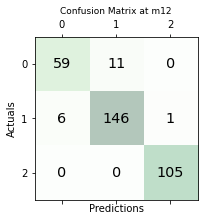

In [32]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Greens, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m12', fontsize=9)
plt.show()

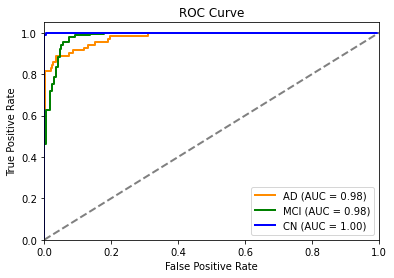

In [33]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# RF on bl&m06&m12.csv (Predict DX at M18)

In [34]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Load the data
import pandas as pd

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12(lessexc).csv')

In [35]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,DX,DX_m18
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3234.0,0.629,2117.0,6979.0,2362.0,601.400000,251.700000,24.180000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,3112.0,0.570,2175.0,905.0,1894.0,472.800000,334.100000,34.040000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2791.0,0.673,1713.0,737.0,2124.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2928.0,0.592,2087.0,681.0,1808.0,340.000000,287.700000,27.370000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,3186.0,0.728,2700.0,2115.0,2302.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2883.0,0.689,2375.0,2487.0,1481.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3320.0,0.663,3072.0,129.0,2356.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


In [36]:
# Create the training and testing feature and label sets
x=data.iloc[:,1:-1] ## independent features
y=data.iloc[:,-1] ## dependent features

In [37]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30,random_state=42)

In [38]:
x_train

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,DX
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,3610.0,2321.0,0.532,1364.0,1527.0,2351.0,843.300000,549.200000,54.940000,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,5409.0,3960.0,0.628,2427.0,1405.0,2340.0,695.300000,237.700000,22.110000,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,4612.0,4180.0,0.599,3030.0,2633.0,1907.0,1459.000000,250.100000,21.350000,0
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,4458.0,2948.0,0.553,2513.0,2258.0,1456.0,1064.913718,284.614621,27.130365,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,6176.0,2742.0,0.530,2610.0,256.0,2000.0,1535.000000,142.500000,12.620000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,3944.0,2673.0,0.755,2384.0,464.0,1992.0,1064.913718,284.614621,27.130365,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,4386.0,2436.0,0.342,1226.0,933.0,2585.0,1064.913718,284.614621,27.130365,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,3396.0,4068.0,0.571,2092.0,3552.0,1577.0,360.600000,118.000000,10.410000,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,3261.0,3872.0,0.478,2377.0,1087.0,1702.0,927.500000,106.300000,8.870000,1


In [39]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create a Random Forest classifier
clf = RandomForestClassifier(random_state=1)

In [40]:
# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=1), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]})

In [41]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 50}
Best score: 0.9685844513243893


In [42]:
# Train a Random Forest classifier on the training set
# Train the ExtraTrees classifier with the best hyperparameters
clf = RandomForestClassifier(**best_params)
clf.fit(x_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_split=5)

In [43]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [44]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 1.0
Testing accuracy: 0.9512195121951219
Confusion matrix:
 [[ 71  12   0]
 [  3 136   1]
 [  0   0 105]]


In [45]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.86      0.90        83
           1       0.92      0.97      0.94       140
           2       0.99      1.00      1.00       105

    accuracy                           0.95       328
   macro avg       0.96      0.94      0.95       328
weighted avg       0.95      0.95      0.95       328



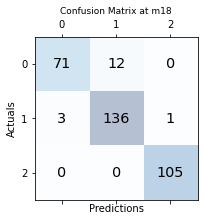

In [46]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m18', fontsize=9)
plt.show()

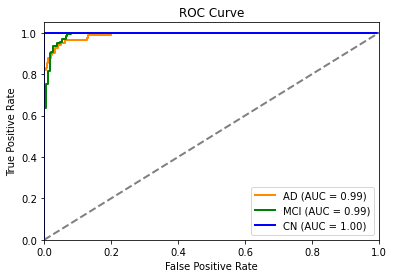

In [47]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# RF on bl&m06&m12&m18.csv (Predict DX at M24)

In [81]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, classification_report
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Load the data
import pandas as pd

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12&m18(lessexc).csv')

In [82]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,DX_m18,DX_m24
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3234.0,0.629,2117.0,6979.0,2362.0,601.400000,251.700000,24.180000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,3112.0,0.570,2175.0,905.0,1894.0,472.800000,334.100000,34.040000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2745.0,0.644,1747.0,827.0,1954.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2928.0,0.592,2087.0,681.0,1808.0,340.000000,287.700000,27.370000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,3186.0,0.728,2700.0,2115.0,2302.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2883.0,0.689,2375.0,2487.0,1481.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3320.0,0.663,3072.0,129.0,2356.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


In [83]:
# Create the training and testing feature and label sets
x=data.iloc[:,1:-1] ## independent features
y=data.iloc[:,-1] ## dependent features

In [84]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30,random_state=42)

In [85]:
x_train

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,DX_m18
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,3610.0,2321.0,0.532,1364.0,1527.0,2351.0,843.300000,549.200000,54.940000,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,5409.0,3960.0,0.628,2427.0,1405.0,2340.0,695.300000,237.700000,22.110000,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,4612.0,4180.0,0.599,3030.0,2633.0,1907.0,1459.000000,250.100000,21.350000,0
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,4458.0,2948.0,0.553,2513.0,2258.0,1456.0,1064.913718,284.614621,27.130365,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,6176.0,2742.0,0.530,2610.0,256.0,2000.0,1535.000000,142.500000,12.620000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,3944.0,2673.0,0.755,2384.0,464.0,1992.0,1064.913718,284.614621,27.130365,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,4386.0,2436.0,0.342,1226.0,933.0,2585.0,1064.913718,284.614621,27.130365,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,3396.0,4068.0,0.571,2092.0,3552.0,1577.0,360.600000,118.000000,10.410000,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,3261.0,3872.0,0.478,2377.0,1087.0,1702.0,927.500000,106.300000,8.870000,1


In [86]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create a Random Forest classifier
clf = RandomForestClassifier(random_state=1)

In [87]:
# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=1), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]})

In [88]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Best parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best score: 0.9201410388716891


In [89]:
# Train a Random Forest classifier on the training set
# Train the ExtraTrees classifier with the best hyperparameters
clf = RandomForestClassifier(**best_params)
clf.fit(x_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_split=10, n_estimators=200)

In [90]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [91]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9869109947643979
Testing accuracy: 0.9298780487804879
Confusion matrix:
 [[ 92  15   0]
 [  4 112   4]
 [  0   0 101]]


In [92]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.86      0.91       107
           1       0.88      0.93      0.91       120
           2       0.96      1.00      0.98       101

    accuracy                           0.93       328
   macro avg       0.93      0.93      0.93       328
weighted avg       0.93      0.93      0.93       328



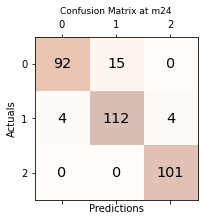

In [93]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Oranges, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m24', fontsize=9)
plt.show()

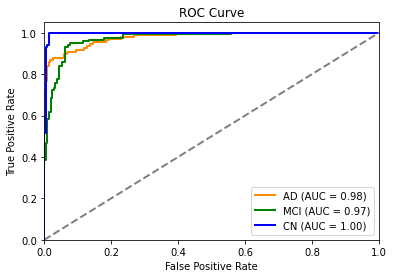

In [94]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

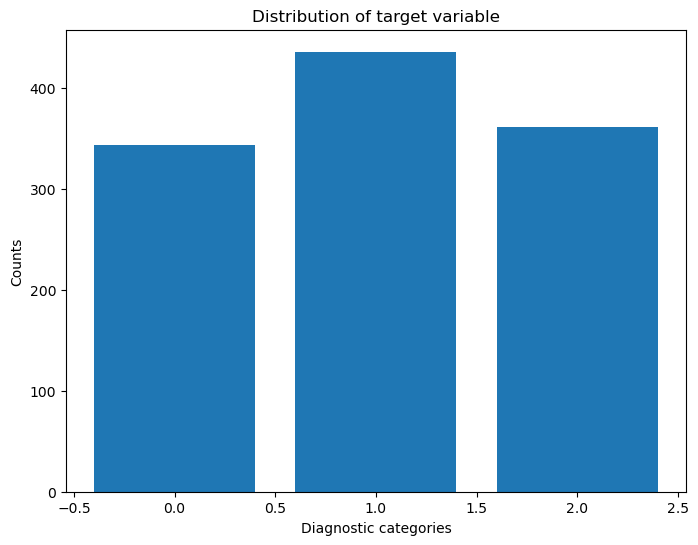

In [9]:
plt.figure(figsize=(8,6))
plt.bar(y.value_counts().index, y.value_counts().values)
plt.title('Distribution of target variable')
plt.xlabel('Diagnostic categories')
plt.ylabel('Counts')
plt.show()

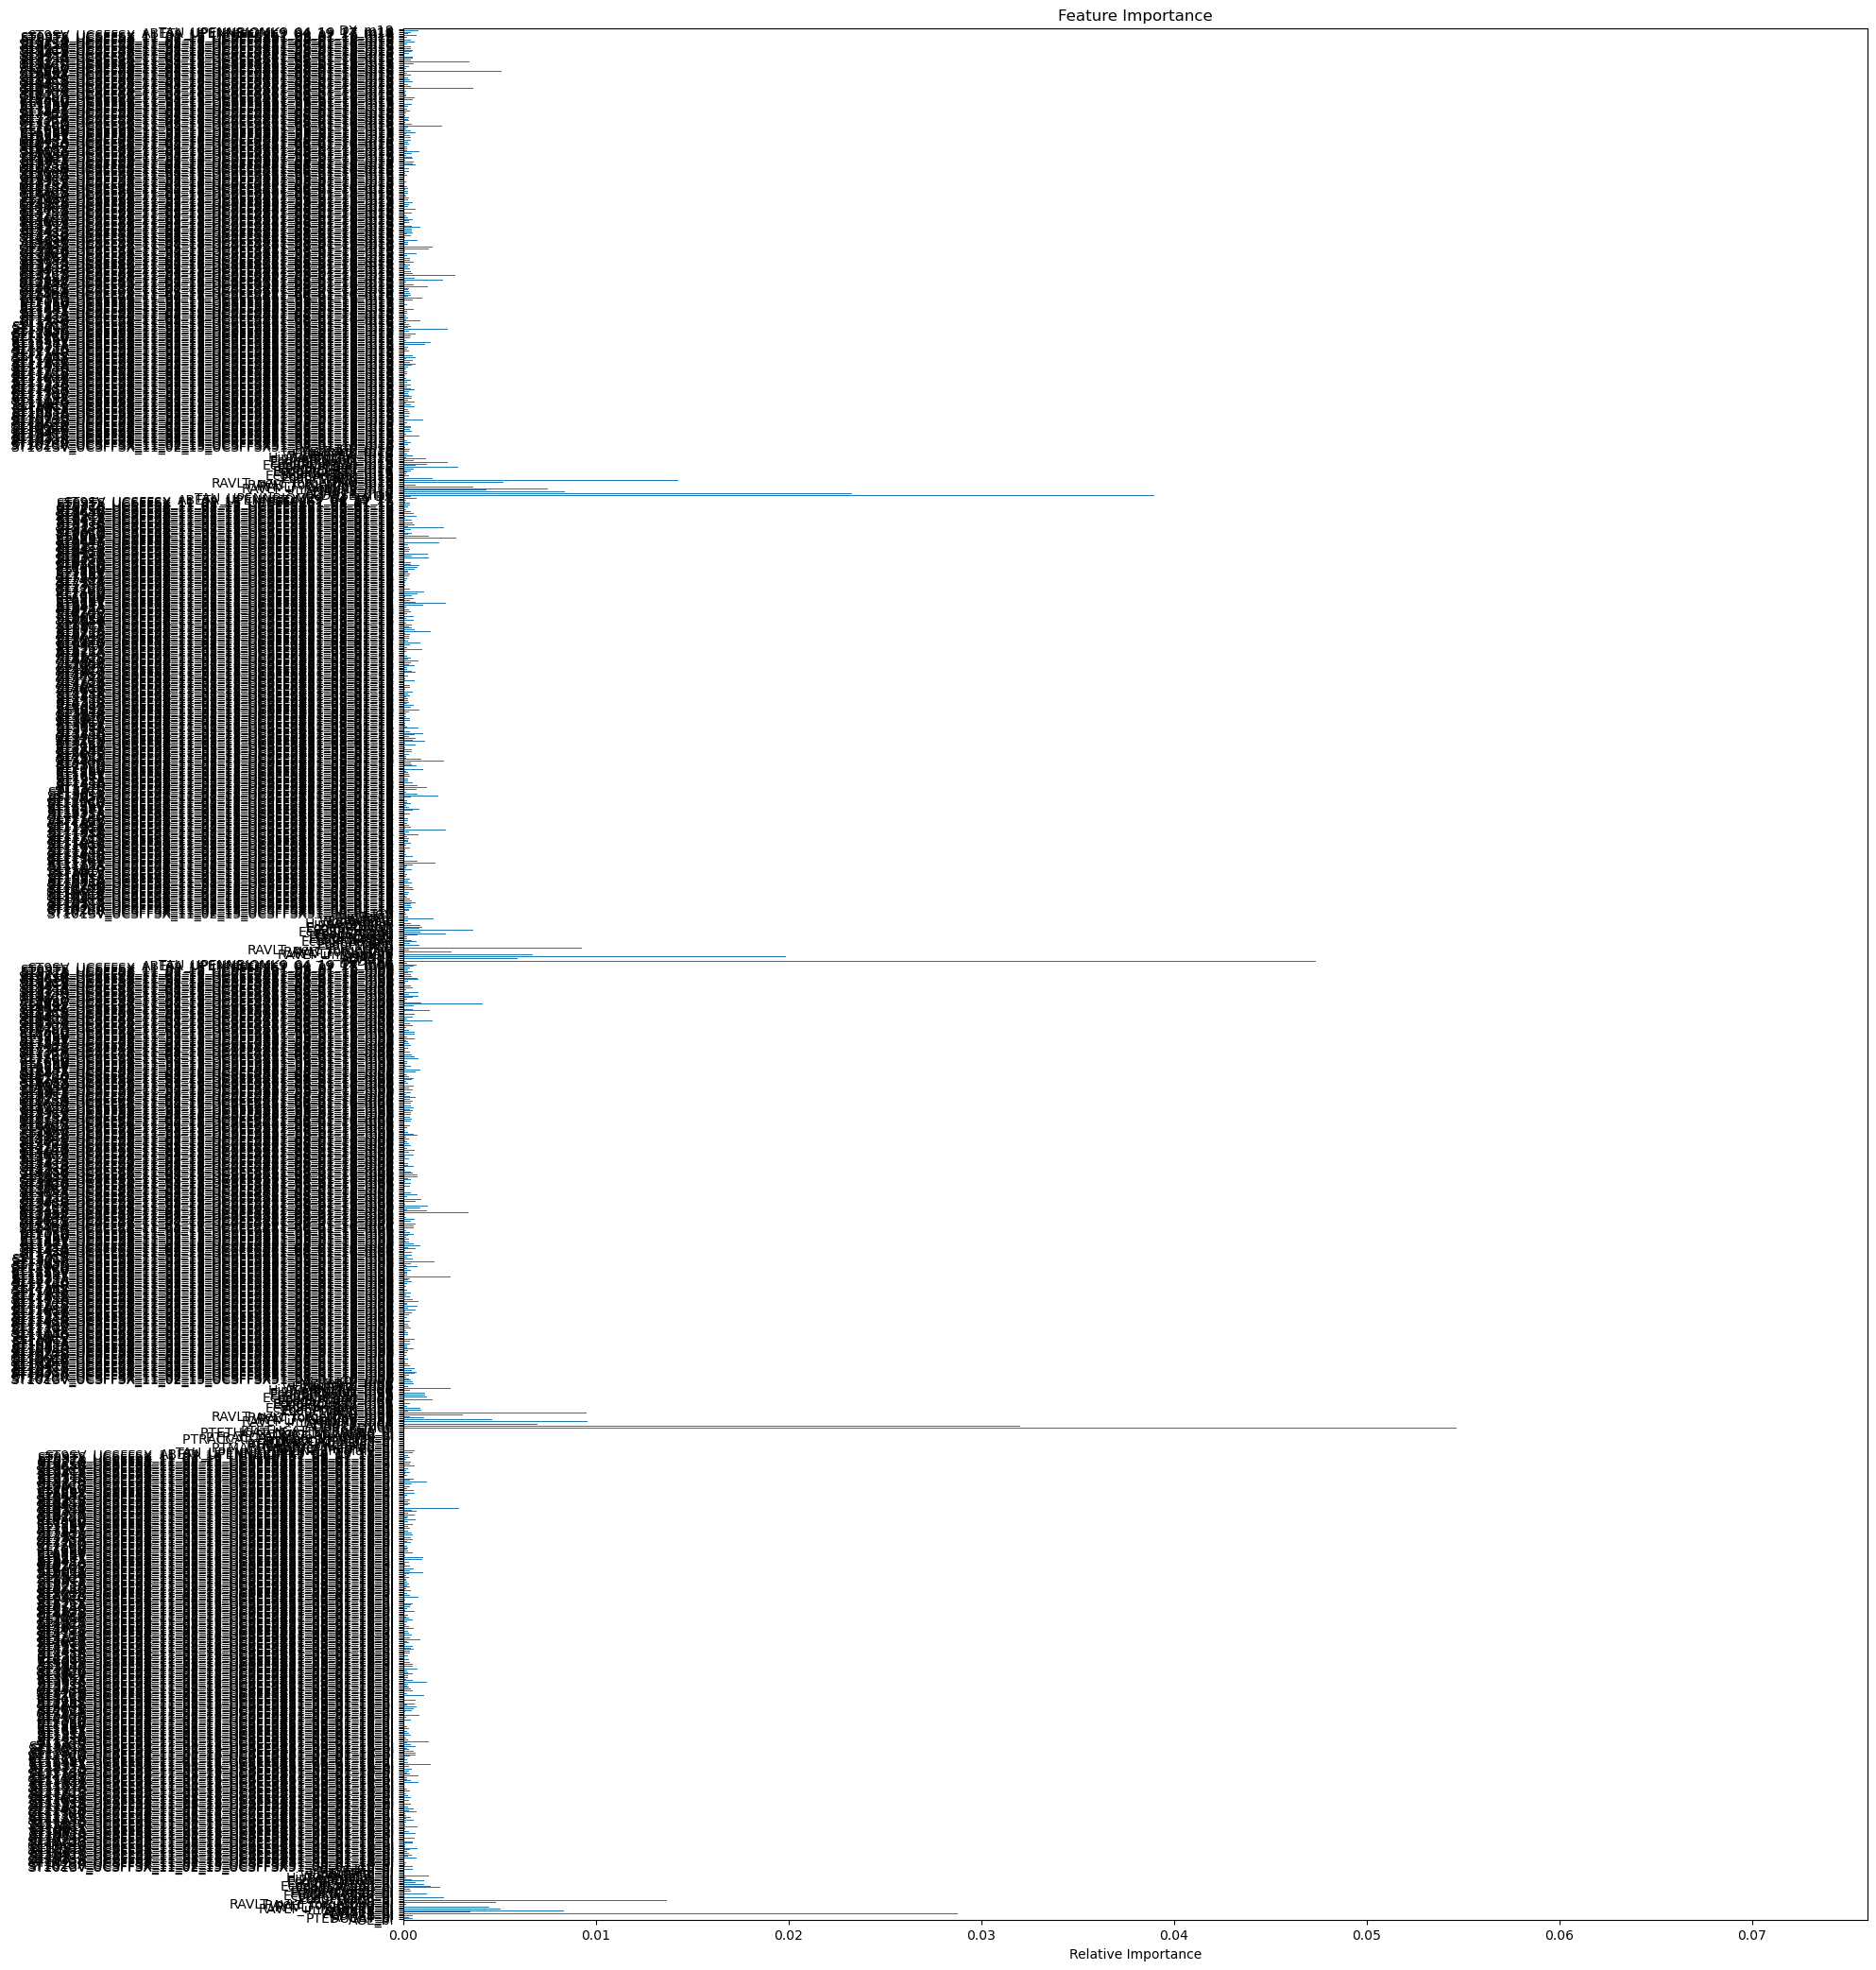

In [12]:
importance = pd.Series(clf.feature_importances_, index=x.columns)
importance.plot(kind='barh', figsize=(20,26))
plt.title('Feature Importance')
plt.xlabel('Relative Importance')
plt.show()